# Regional Waste Profile Clustering & Prediction of Indonesian Regencies/Cities

## 0. Setup

In [4]:
!pip install pandas numpy scikit-learn matplotlib seaborn scipy pdfplumber openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 45.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 72.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 73.8 MB/s  0:00:00
  Attempting uninstall: pillow
    Found existing installation: pillow 11.3.0
    Uninstalling pillow-11.3.0:
      Successfully uninstalled pillow-11.3.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [pdfplumber]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings
import pdfplumber
from pathlib import Path

from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA
from sklearn.impute import KNNImputer
from sklearn.ensemble import RandomForestClassifier

from scipy.stats import mstats

import requests

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120

In [6]:


PROC_DIR = Path('processed'); PROC_DIR.mkdir(exist_ok=True)
FIG_DIR = Path('figures');   FIG_DIR.mkdir(exist_ok=True)

GITHUB_RAW = 'https://raw.githubusercontent.com/PoisonAifih/AOL_Datmin/main'

YEARS = [2020, 2021, 2022, 2023, 2024, 2025]
WASTE_COLS = ['sisa_makanan','kayu_ranting','kertas_karton','plastik',
              'logam','kain','karet_kulit','kaca','lainnya']

DISPLAY_LABELS = {
    'sisa_makanan': 'Food waste', 'kayu_ranting': 'Wood/twigs',
    'kertas_karton': 'Paper/cardboard', 'plastik': 'Plastic',
    'logam': 'Metal', 'kain': 'Textile', 'karet_kulit': 'Rubber/leather',
    'kaca': 'Glass', 'lainnya': 'Other',
    'timbulan_harian': 'Daily generation', 'timbulan_tahunan': 'Annual generation',
    'jumlah_penduduk': 'Population', 'kepadatan_km2': 'Density (per km2)',
    'pdrb_miliar': 'GRDP (billion)', 'pdrb_per_kapita': 'GRDP per capita',
    'is_kota': 'Is city', 'kabkota': 'Regency/City', 'provinsi': 'Province',
    'tahun': 'Year', 'n_daerah': 'n_regions', 'n_kota': 'n_cities',
}

def _gh_download(remote_path: str, dest: Path) -> None:
    if dest.exists():
        return
    url = f'{GITHUB_RAW}/{remote_path}'
    print(f'  ↓ {dest.name} ...', end=' ')
    r = requests.get(url, timeout=60)
    r.raise_for_status()
    dest.write_bytes(r.content)
    print('ok')

KOMP_DIR = PROC_DIR / 'Data_Komposisi_Jenis_Sampah'; KOMP_DIR.mkdir(exist_ok=True)
TIMB_DIR = PROC_DIR / 'Data_Timbulan_Sampah'; TIMB_DIR.mkdir(exist_ok=True)

print('Fetching data from GitHub...')

for yr in YEARS:
    _gh_download(
        f'Data_Komposisi_Jenis_Sampah/Data_Komposisi_Jenis_Sampah_SIPSN_KLHK_{yr}.xlsx',
        KOMP_DIR / f'Data_Komposisi_Jenis_Sampah_SIPSN_KLHK_{yr}.xlsx'
    )
    _gh_download(
        f'Data_Timbulan_Sampah/Data_Timbulan_Sampah_SIPSN_KLHK_{yr}.xlsx',
        TIMB_DIR / f'Data_Timbulan_Sampah_SIPSN_KLHK_{yr}.xlsx'
    )

DUC_FILE = PROC_DIR / 'Data-dukcapil_jumlah_penduduk_kabkot-2018-2023.xlsx'
_gh_download('Data-dukcapil_jumlah_penduduk_kabkot-2018-2023.xlsx', DUC_FILE)

PDF_FILE = PROC_DIR / 'produk-domestik-regional-bruto-kabupaten-kota-di-indonesia-2020-2024.pdf'
_gh_download(
    'produk-domestik-regional-bruto-kabupaten-kota-di-indonesia-2020-2024.pdf',
    PDF_FILE
)

print('Setup complete.')

Fetching data from GitHub...
  ↓ Data_Komposisi_Jenis_Sampah_SIPSN_KLHK_2020.xlsx ... ok
  ↓ Data_Timbulan_Sampah_SIPSN_KLHK_2020.xlsx ... ok
  ↓ Data_Komposisi_Jenis_Sampah_SIPSN_KLHK_2021.xlsx ... ok
  ↓ Data_Timbulan_Sampah_SIPSN_KLHK_2021.xlsx ... ok
  ↓ Data_Komposisi_Jenis_Sampah_SIPSN_KLHK_2022.xlsx ... ok
  ↓ Data_Timbulan_Sampah_SIPSN_KLHK_2022.xlsx ... ok
  ↓ Data_Komposisi_Jenis_Sampah_SIPSN_KLHK_2023.xlsx ... ok
  ↓ Data_Timbulan_Sampah_SIPSN_KLHK_2023.xlsx ... ok
  ↓ Data_Komposisi_Jenis_Sampah_SIPSN_KLHK_2024.xlsx ... ok
  ↓ Data_Timbulan_Sampah_SIPSN_KLHK_2024.xlsx ... ok
  ↓ Data_Komposisi_Jenis_Sampah_SIPSN_KLHK_2025.xlsx ... ok
  ↓ Data_Timbulan_Sampah_SIPSN_KLHK_2025.xlsx ... ok
  ↓ Data-dukcapil_jumlah_penduduk_kabkot-2018-2023.xlsx ... ok
  ↓ produk-domestik-regional-bruto-kabupaten-kota-di-indonesia-2020-2024.pdf ... ok
Setup complete.


## 1.Name normalisation
Since all three sources use different name formats.  

In [7]:
def normalize_name(s):
    s = str(s).strip().upper()
    s = re.sub(r'^(KAB\.|KOTA|KABUPATEN|KOTAMADYA)\s*', '', s).strip()
    return s

def is_kota(s):
    return int(str(s).strip().lower().startswith('kota'))

tests = [('Kab. Aceh Timur', 'KAB. ACEH TIMUR'),
         ('Kota Banda Aceh', 'KOTA BANDA ACEH'),
         ('Kab. Simeulue',   'KAB. SIMEULUE')]
for a, b in tests:
    assert normalize_name(a) == normalize_name(b), f'Mismatch: {a} vs {b}'
print('Name normalisation: all tests passed.')

Name normalisation: all tests passed.


## 2. Load data
### 2.1 SIPSN —> waste composition (2020–2025)

In [8]:
KOMP_RENAME = {
    'Tahun': 'tahun', 'Provinsi': 'provinsi', 'Kabupaten/Kota': 'kabkota',
    'Sisa Makanan (%)': 'sisa_makanan', 'Kayu-Ranting (%)': 'kayu_ranting',
    'Kertas-Karton (%)': 'kertas_karton', 'Plastik(%)': 'plastik',
    'Logam(%)': 'logam', 'Kain(%)': 'kain', 'Karet- Kulit (%)': 'karet_kulit',
    'Kaca(%)': 'kaca', 'Lainnya(%)': 'lainnya'
}

frames = []
for yr in YEARS:
    f = KOMP_DIR / f'Data_Komposisi_Jenis_Sampah_SIPSN_KLHK_{yr}.xlsx'
    df = pd.read_excel(f, header=1).rename(columns=KOMP_RENAME)
    frames.append(df)

df_komp = pd.concat(frames, ignore_index=True)
df_komp['tahun'] = pd.to_numeric(df_komp['tahun'], errors='coerce')
for c in WASTE_COLS:
    df_komp[c] = pd.to_numeric(df_komp[c], errors='coerce')

df_komp['kabkota_key'] = df_komp['kabkota'].apply(normalize_name)
df_komp['is_kota'] = df_komp['kabkota'].apply(is_kota)

print(f'Composition: {len(df_komp)} rows | {df_komp.kabkota_key.nunique()} unique regency/city | {df_komp.tahun.nunique()} years')
print(f'Missing per waste col (%):')
print((df_komp[WASTE_COLS].isna().mean() * 100).round(1).rename(DISPLAY_LABELS).to_string())

Composition: 1829 rows | 433 unique regency/city | 6 years
Missing per waste col (%):
Food waste         21.0
Wood/twigs         24.2
Paper/cardboard    20.5
Plastic            20.4
Metal              22.7
Textile            25.1
Rubber/leather     28.9
Glass              24.9
Other              25.9


### 2.2 SIPSN —> waste generation (2020–2025)

In [9]:
TIMB_RENAME = {
    'Tahun': 'tahun', 'Provinsi': 'provinsi', 'Kabupaten/Kota': 'kabkota',
    'Timbulan Sampah Harian(ton)': 'timbulan_harian',
    'Timbulan Sampah Tahunan(ton)': 'timbulan_tahunan'
}

frames = []
for yr in YEARS:
    f = TIMB_DIR / f'Data_Timbulan_Sampah_SIPSN_KLHK_{yr}.xlsx'
    df = pd.read_excel(f, header=1).rename(columns=TIMB_RENAME)
    frames.append(df)

df_timb = pd.concat(frames, ignore_index=True)
df_timb['tahun'] = pd.to_numeric(df_timb['tahun'], errors='coerce')
df_timb['kabkota_key'] = df_timb['kabkota'].apply(normalize_name)

print(f'Generation: {len(df_timb)} rows | missing: {df_timb.timbulan_harian.isna().sum()}')

Generation: 1829 rows | missing: 0


### 2.3 Dukcapil —> population & density (2018–2023)

In [10]:
df_duc = pd.read_excel(DUC_FILE, header=1)
df_duc.columns = ['id','tahun','semester','provinsi_duc','kabkota','jumlah_penduduk','kepadatan_km2']

df_duc = df_duc[df_duc['tahun'] != 'tahun'].copy()
df_duc['tahun'] = pd.to_numeric(df_duc['tahun'], errors='coerce')
df_duc['jumlah_penduduk'] = pd.to_numeric(df_duc['jumlah_penduduk'], errors='coerce')
df_duc['kepadatan_km2'] = pd.to_numeric(df_duc['kepadatan_km2'], errors='coerce')
df_duc = df_duc.dropna(subset=['tahun'])

df_duc = df_duc[df_duc['kabkota'].str.match(r'^[A-Z]', na=False)].copy()

df_duc = (df_duc
    .sort_values(['tahun','kabkota','semester'])
    .drop_duplicates(subset=['tahun','kabkota'], keep='last')
)

df_duc['kabkota_key'] = df_duc['kabkota'].apply(normalize_name)

latest = df_duc[df_duc['tahun']==2023][['kabkota_key','jumlah_penduduk','kepadatan_km2']].copy()
for ext_yr in [2024, 2025]:
    tmp = latest.copy(); tmp['tahun'] = ext_yr
    df_duc = pd.concat([df_duc, tmp], ignore_index=True)

print(f'Dukcapil: {df_duc.kabkota_key.nunique()} unique regency/city | years {sorted(df_duc.tahun.unique())}')

Dukcapil: 512 unique regency/city | years [np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


### 2.4 BPS GRDP (Gross Regional Domestic Product) (extract from PDF)

In [11]:
def extract_pdrb_pdf(pdf_path):
    rows = []
    current_prov = None
    pattern = re.compile(
        r'^\d{2,3}\.\s+((?:Kab\.|Kota|Kabupaten|Kotamadya)?\s*[\w\s\.\-]+?)'
        r'\s+([\d\.]+)\s+([\d\.]+)\s+([\d\.]+)\s+([\d\.]+(?:\*+)?)\s+([\d\.]+(?:\*+)?)'
    )
    with pdfplumber.open(pdf_path) as pdf:
        for page in pdf.pages:
            text = page.extract_text() or ''
            m = re.search(r'PDRB Provinsi ([^\n]+?) Atas Dasar', text)
            if m:
                current_prov = m.group(1).strip()
            for line in text.split('\n'):
                m = pattern.match(line.strip())
                if m:
                    name = m.group(1).strip()
                    vals = [m.group(i).replace('*','').replace('.','') for i in range(2, 7)]
                    try:
                        nums = [float(v) for v in vals]
                        rows.append({
                            'provinsi_pdrb': current_prov,
                            'kabkota_orig': name,
                            'kabkota_key': normalize_name(name),
                            'pdrb_2020': nums[0], 'pdrb_2021': nums[1],
                            'pdrb_2022': nums[2], 'pdrb_2023': nums[3],
                            'pdrb_2024': nums[4],
                        })
                    except:
                        pass
    df = pd.DataFrame(rows).drop_duplicates(subset=['kabkota_key'], keep='first')
    return df

df_pdrb_wide = extract_pdrb_pdf(PDF_FILE)
print(f'GRDP wide: {len(df_pdrb_wide)} regency/city | {df_pdrb_wide.provinsi_pdrb.nunique()} province')

df_pdrb = df_pdrb_wide.melt(
    id_vars=['kabkota_key','provinsi_pdrb','kabkota_orig'],
    value_vars=['pdrb_2020','pdrb_2021','pdrb_2022','pdrb_2023','pdrb_2024'],
    var_name='tahun', value_name='pdrb_miliar'
)
df_pdrb['tahun'] = df_pdrb['tahun'].str.extract(r'(\d{4})').astype(int)
pdrb_2025 = df_pdrb[df_pdrb['tahun']==2024].copy(); pdrb_2025['tahun'] = 2025
df_pdrb = pd.concat([df_pdrb, pdrb_2025], ignore_index=True)
print(f'GRDP long: {len(df_pdrb)} rows | years: {sorted(df_pdrb.tahun.unique())}')

GRDP wide: 357 regency/city | 35 province
GRDP long: 2142 rows | years: [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


## 3. Merge all sources into panel dataset

In [12]:
# composition as base
df = df_komp.copy()

# generation
df = df.merge(
    df_timb[['kabkota_key','tahun','timbulan_harian','timbulan_tahunan']],
    on=['kabkota_key','tahun'], how='left'
)

# Merge population + density
df = df.merge(
    df_duc[['kabkota_key','tahun','jumlah_penduduk','kepadatan_km2']],
    on=['kabkota_key','tahun'], how='left'
)

# Merge GRDP
df = df.merge(
    df_pdrb[['kabkota_key','tahun','pdrb_miliar']],
    on=['kabkota_key','tahun'], how='left'
)

# Derived features
df['pdrb_per_kapita'] = df['pdrb_miliar'] * 1e9 / df['jumlah_penduduk']
df['waste_per_kapita'] = df['timbulan_harian'] * 1000 / df['jumlah_penduduk']
df['covid_dummy'] = df['tahun'].isin([2020, 2021]).astype(int)

print(f'Panel dataset: {df.shape}')
print(f'Unique regency/city: {df.kabkota_key.nunique()}')
print(f'Years: {sorted(df.tahun.dropna().unique())}')
print(f'\nMissing values (%):')
feats = WASTE_COLS + ['timbulan_harian','jumlah_penduduk','kepadatan_km2','pdrb_miliar','pdrb_per_kapita']
print((df[feats].isna().mean()*100).round(1).rename(DISPLAY_LABELS).to_string())

Panel dataset: (2557, 22)
Unique regency/city: 433
Years: [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]

Missing values (%):
Food waste           20.3
Wood/twigs           24.2
Paper/cardboard      19.9
Plastic              19.8
Metal                22.1
Textile              24.2
Rubber/leather       28.7
Glass                24.2
Other                24.8
Daily generation      0.0
Population            0.8
Density (per km2)     0.8
GRDP (billion)       26.6
GRDP per capita      26.9


---
## 4. Preprocessing
### 4.1 Missing value overview (EDA)

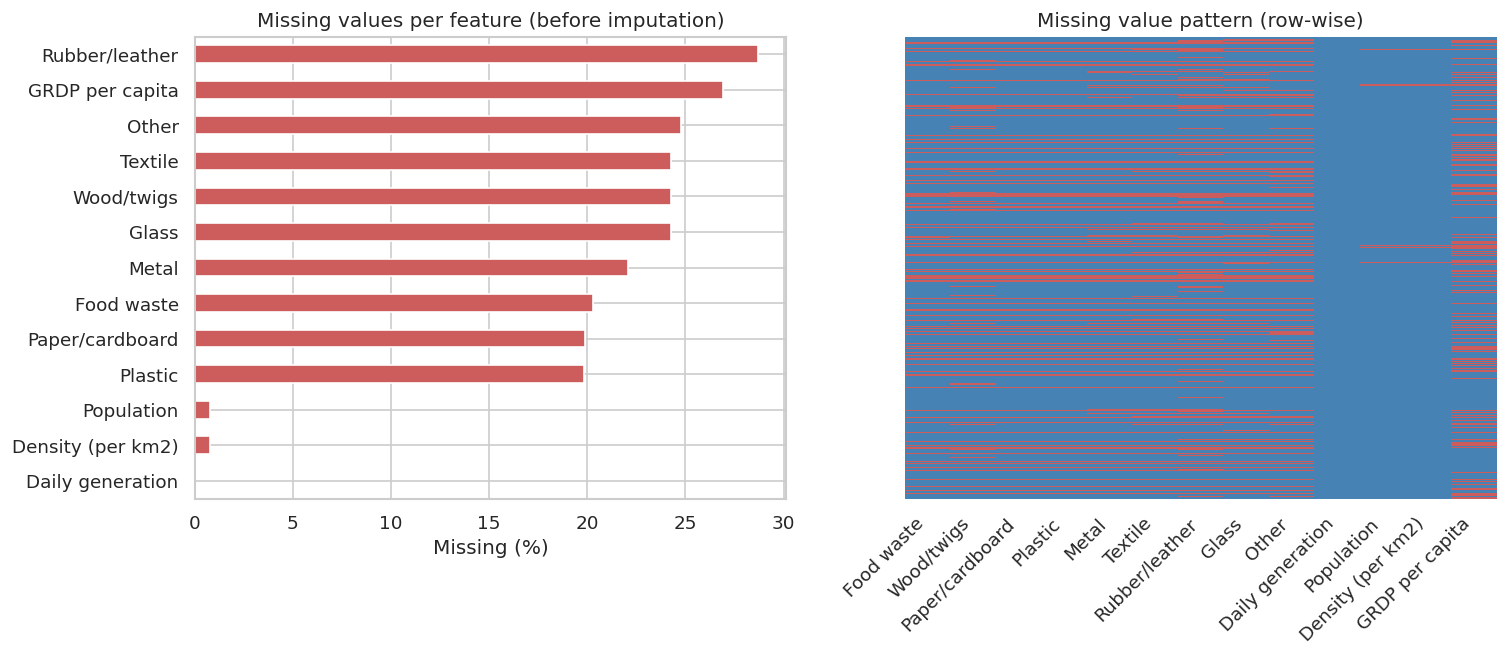

In [13]:
FEATURE_COLS = WASTE_COLS + ['timbulan_harian','jumlah_penduduk','kepadatan_km2','pdrb_per_kapita']

missing_pct = (df[FEATURE_COLS].isna().mean() * 100).rename(DISPLAY_LABELS).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

missing_pct.plot.barh(ax=axes[0], color='indianred', edgecolor='white')
axes[0].set_xlabel('Missing (%)')
axes[0].set_title('Missing values per feature (before imputation)')
axes[0].invert_yaxis()

sns.heatmap(
    df[FEATURE_COLS].rename(columns=DISPLAY_LABELS).isna(),
    cbar=False, yticklabels=False, cmap=['steelblue', 'indianred'], ax=axes[1]
)
axes[1].set_title('Missing value pattern (row-wise)')
axes[1].set_xlabel('')
plt.setp(axes[1].get_xticklabels(), rotation=45, ha='right')

plt.show()

### 4.2 Impute missing values (KNN)

In [14]:
df_before_clean = df[FEATURE_COLS].copy()

imputer = KNNImputer(n_neighbors=5)
df[FEATURE_COLS] = imputer.fit_transform(df[FEATURE_COLS])

for col in FEATURE_COLS:
    df[col] = mstats.winsorize(df[col], limits=[0.01, 0.01])

df['comp_sum'] = df[WASTE_COLS].sum(axis=1)
bad_rows = (df['comp_sum'] < 80) | (df['comp_sum'] > 120)
print(f'Rows with composition sum outside 80–120%: {bad_rows.sum()}')
df = df[~bad_rows].copy()
df.drop(columns=['comp_sum'], inplace=True)

print(f'After cleaning: {df.shape}')
print('Missing remaining:', df[FEATURE_COLS].isna().sum().sum())

Rows with composition sum outside 80–120%: 64
After cleaning: (2493, 22)
Missing remaining: 0


### 4.3 Before vs. after imputation & outlier handling (EDA)

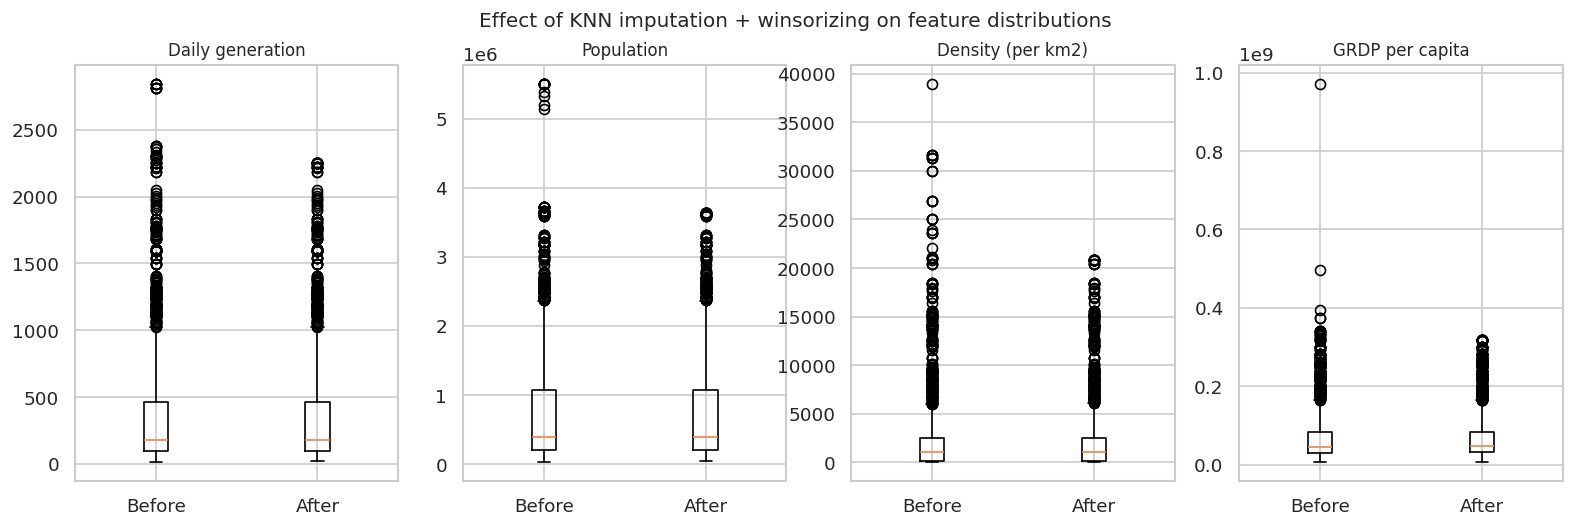

In [15]:
compare_cols = ['timbulan_harian', 'jumlah_penduduk', 'kepadatan_km2', 'pdrb_per_kapita']

fig, axes = plt.subplots(1, len(compare_cols), figsize=(4*len(compare_cols), 4.5))
for ax, col in zip(axes, compare_cols):
    before = df_before_clean.loc[df.index, col]
    after = df[col]
    ax.boxplot([before.dropna(), after])
    ax.set_xticks([1, 2])
    ax.set_xticklabels(['Before', 'After'])
    ax.set_title(DISPLAY_LABELS.get(col, col), fontsize=10)

plt.suptitle('Effect of KNN imputation + winsorizing on feature distributions', fontsize=12)
plt.show()

### 4.4 Cross-sectional dataset (mean per regency/city across years)
Used for clustering —> one row per region.

In [16]:
df_cross = (
    df.groupby('kabkota_key')[FEATURE_COLS + ['is_kota']].mean().reset_index()
)
df_cross = df_cross.merge(
    df.groupby('kabkota_key')[['kabkota','provinsi']].first().reset_index(),
    on='kabkota_key'
)
df_cross['is_kota'] = df_cross['is_kota'].round().astype(int)

print(f'Cross-sectional: {df_cross.shape}')
df_cross.head(3)

Cross-sectional: (430, 17)


,kabkota_key,sisa_makanan,kayu_ranting,kertas_karton,plastik,logam,kain,karet_kulit,kaca,lainnya,timbulan_harian,jumlah_penduduk,kepadatan_km2,pdrb_per_kapita,is_kota,kabkota,provinsi
0,ACEH BARAT,48.2125,10.8925,7.9875,20.785,2.925,3.0575,1.4925,1.5825,3.065,97.307500,201003.75,2104.134036,6.765742e+07,0,Kab. Aceh Barat,Aceh
1,ACEH BARAT DAYA,25.0750,7.3750,22.5000,19.750,10.500,2.6750,3.6250,3.7500,4.750,79.010000,154294.25,1437.454932,3.280046e+07,0,Kab. Aceh Barat Daya,Aceh
2,ACEH BESAR,25.5000,25.5000,9.5000,21.600,5.100,3.3000,3.3000,3.7000,2.500,149.703333,432491.00,2891.477000,4.153612e+07,0,Kab. Aceh Besar,Aceh


### 4.5 Normalise features for clustering

In [17]:
scaler = MinMaxScaler()
X = scaler.fit_transform(df_cross[FEATURE_COLS])
X_df = pd.DataFrame(X, columns=FEATURE_COLS, index=df_cross['kabkota_key'])
print(f'Feature matrix X: {X.shape}')

Feature matrix X: (430, 13)


---
## 5. Exploratory Data Analysis

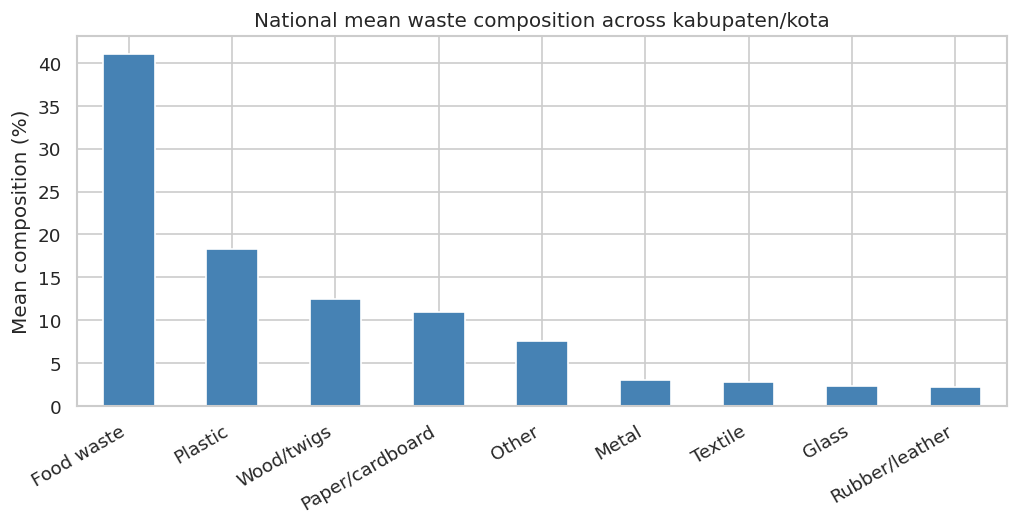

In [18]:
nat_mean = df_cross[WASTE_COLS].mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 4))
nat_mean.plot.bar(ax=ax, color='steelblue', edgecolor='white')
ax.set_ylabel('Mean composition (%)')
ax.set_title('National mean waste composition across kabupaten/kota')
ax.set_xticklabels([DISPLAY_LABELS.get(c, c) for c in nat_mean.index], rotation=30, ha='right')
plt.show()

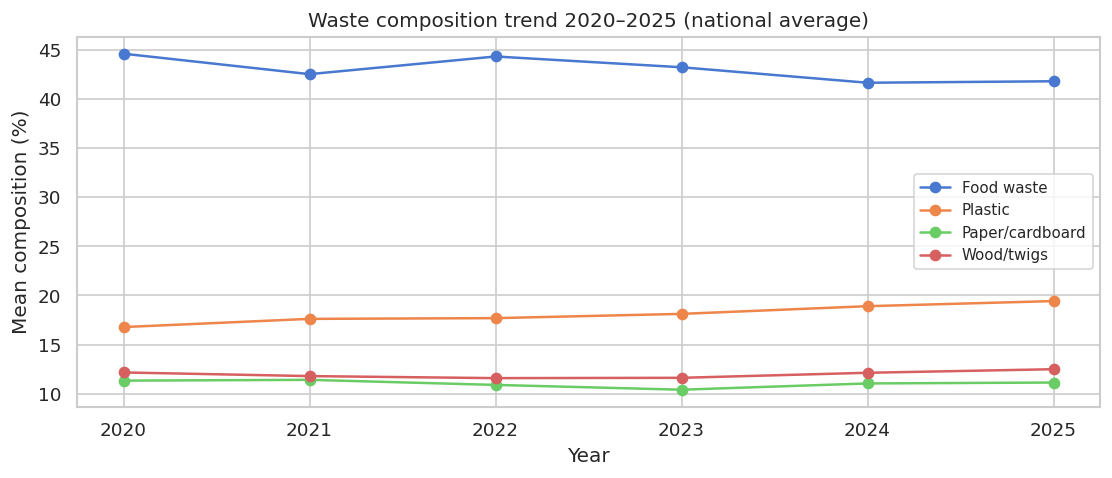

In [19]:
trend = df.groupby('tahun')[WASTE_COLS].mean()
fig, ax = plt.subplots(figsize=(11, 4))
for col in ['sisa_makanan','plastik','kertas_karton','kayu_ranting']:
    ax.plot(trend.index, trend[col], marker='o', label=DISPLAY_LABELS.get(col, col))
ax.set_xlabel('Year')
ax.set_ylabel('Mean composition (%)')
ax.set_title('Waste composition trend 2020–2025 (national average)')
ax.legend(fontsize=9)
plt.show()

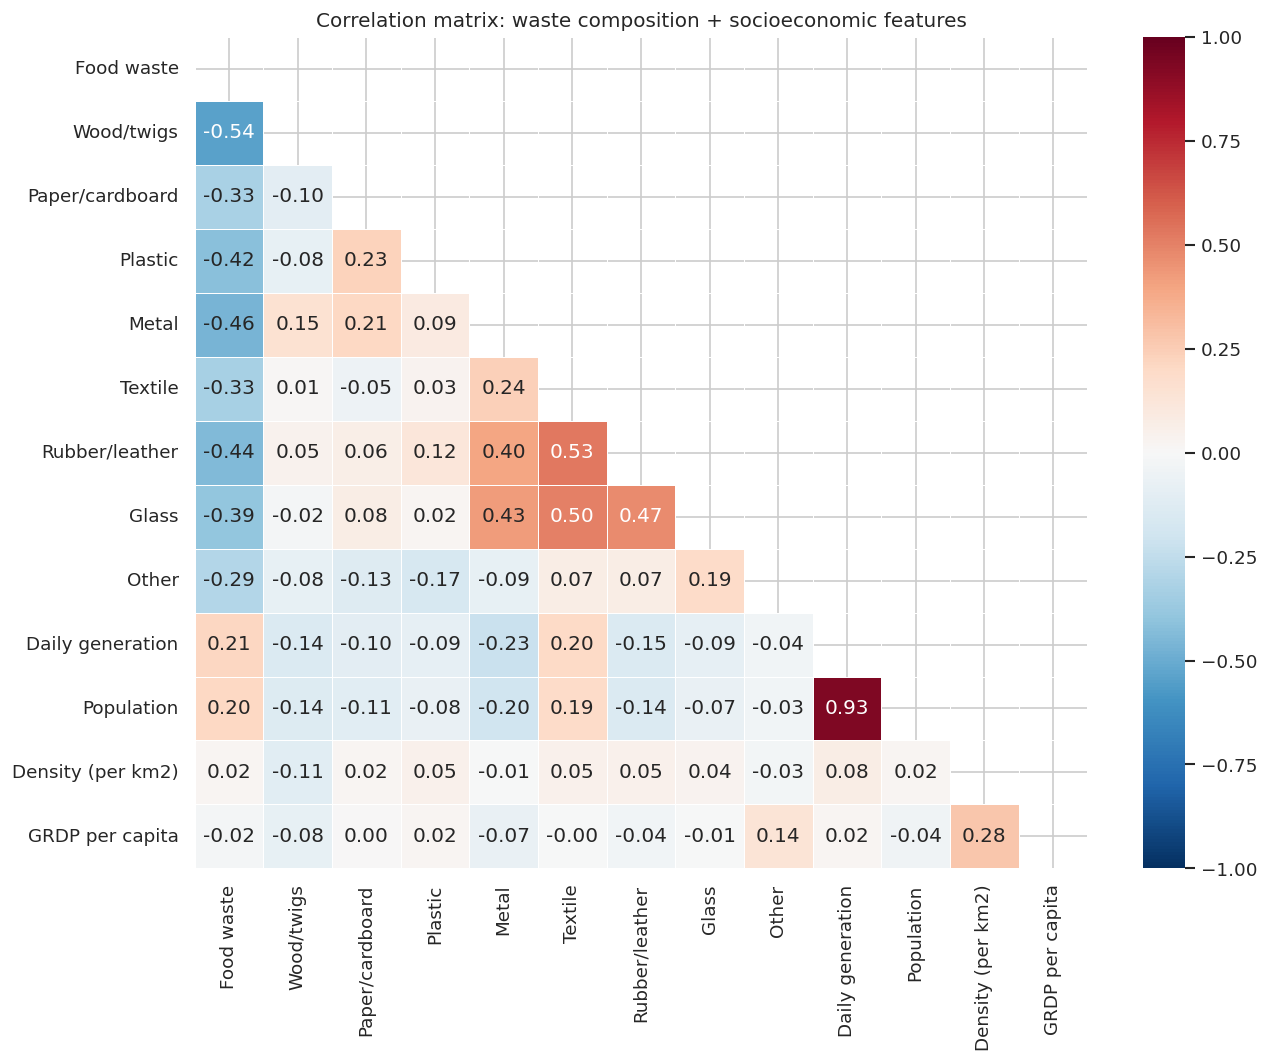

In [20]:
corr = df_cross[FEATURE_COLS].corr().rename(index=DISPLAY_LABELS, columns=DISPLAY_LABELS)
fig, ax = plt.subplots(figsize=(12, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, linewidths=0.4, ax=ax)
ax.set_title('Correlation matrix: waste composition + socioeconomic features')
plt.show()

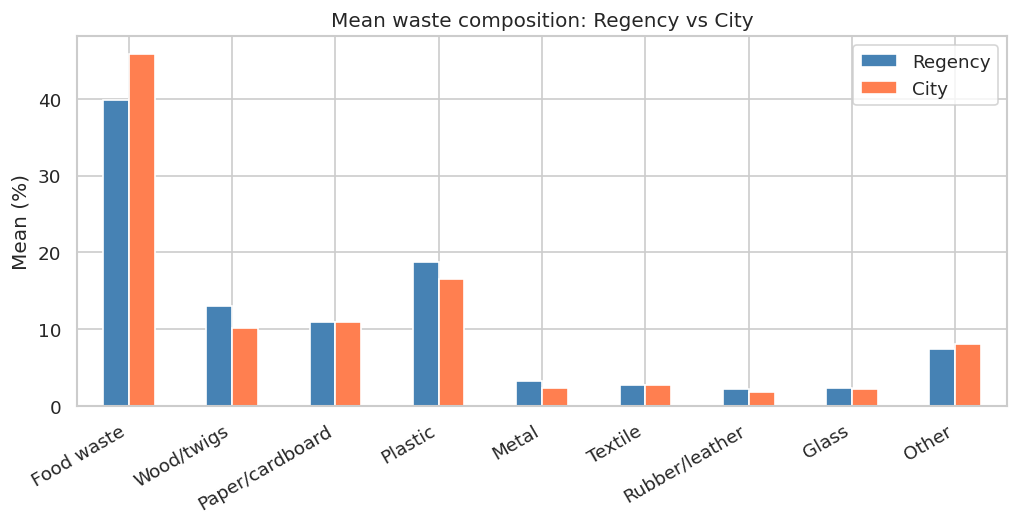

In [21]:
comp_by_type = df_cross.groupby('is_kota')[WASTE_COLS].mean().T
comp_by_type.columns = ['Regency','City']
fig, ax = plt.subplots(figsize=(10, 4))
comp_by_type.plot.bar(ax=ax, color=['steelblue','coral'], edgecolor='white')
ax.set_title('Mean waste composition: Regency vs City')
ax.set_xticklabels([DISPLAY_LABELS.get(c, c) for c in comp_by_type.index], rotation=30, ha='right')
ax.set_ylabel('Mean (%)')
ax.legend()
plt.show()

---
## 6. Clustering
### 6.1 Determine optimal K

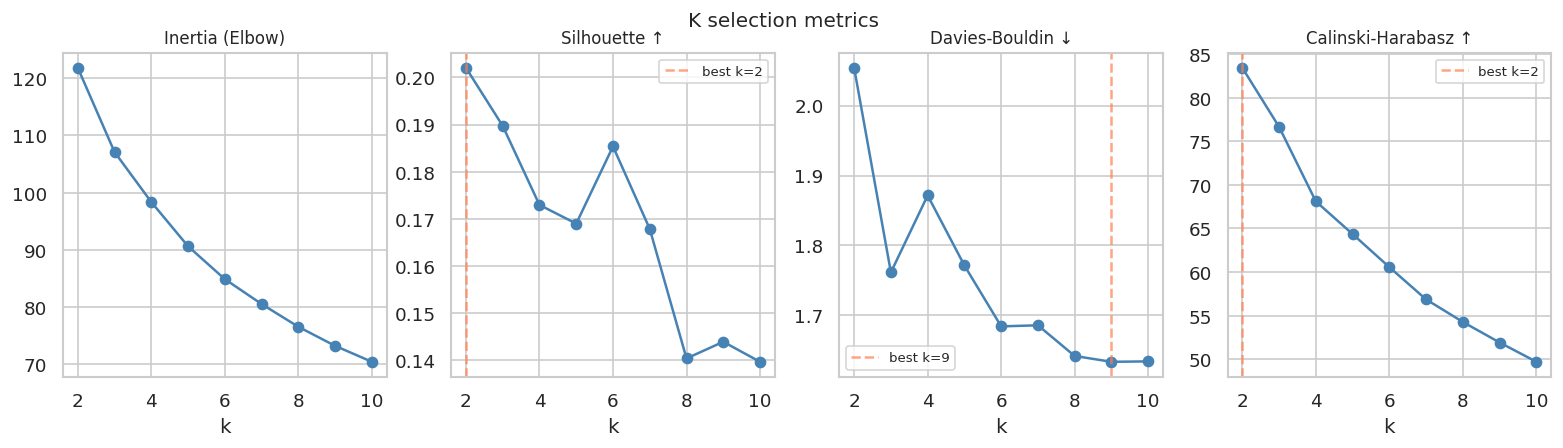

,inertia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,121.7886,0.2020,2.0540,83.4286
3,107.0821,0.1897,1.7615,76.6544
4,98.3544,0.1729,1.8715,68.1080
5,90.6324,0.1690,1.7714,64.3557
6,84.8985,0.1853,1.6843,60.5596
7,80.5571,0.1678,1.6858,56.8601
8,76.5817,0.1403,1.6420,54.2755
9,73.2560,0.1439,1.6337,51.9184
10,70.4703,0.1396,1.6342,49.7048


In [22]:
K_RANGE = range(2, 11)
inertias, sil_scores, db_scores, ch_scores = [], [], [], []

for k in K_RANGE:
    km = KMeans(n_clusters=k, init='k-means++', n_init=20, random_state=42)
    labels = km.fit_predict(X)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X, labels))
    db_scores.append(davies_bouldin_score(X, labels))
    ch_scores.append(calinski_harabasz_score(X, labels))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, vals, title, best_fn in zip(
    axes,
    [inertias, sil_scores, db_scores, ch_scores],
    ['Inertia (Elbow)', 'Silhouette ↑', 'Davies-Bouldin ↓', 'Calinski-Harabasz ↑'],
    [None, max, min, max]
):
    ax.plot(list(K_RANGE), vals, 'o-', color='steelblue')
    ax.set_xlabel('k')
    ax.set_title(title, fontsize=10)
    if best_fn:
        bk = list(K_RANGE)[vals.index(best_fn(vals))]
        ax.axvline(bk, color='coral', linestyle='--', alpha=0.7, label=f'best k={bk}')
        ax.legend(fontsize=8)

plt.suptitle('K selection metrics', fontsize=12)
plt.show()

pd.DataFrame({'k': list(K_RANGE), 'inertia': inertias,'silhouette': sil_scores, 'davies_bouldin': db_scores, 'calinski_harabasz': ch_scores}).set_index('k').round(4)

### 6.2 K-Means — final model

In [23]:
# There's no really best K so take 5 as middle, not too little not too much
BEST_K = 5

km_final = KMeans(n_clusters=BEST_K, init='k-means++', n_init=30, random_state=42)
df_cross['cluster_kmeans'] = km_final.fit_predict(X)

print(f'K-Means (k={BEST_K})')
print(df_cross['cluster_kmeans'].value_counts().sort_index())

K-Means (k=5)
cluster_kmeans
0    197
1    110
2     34
3     37
4     52
Name: count, dtype: int64


### 6.4 DBSCAN

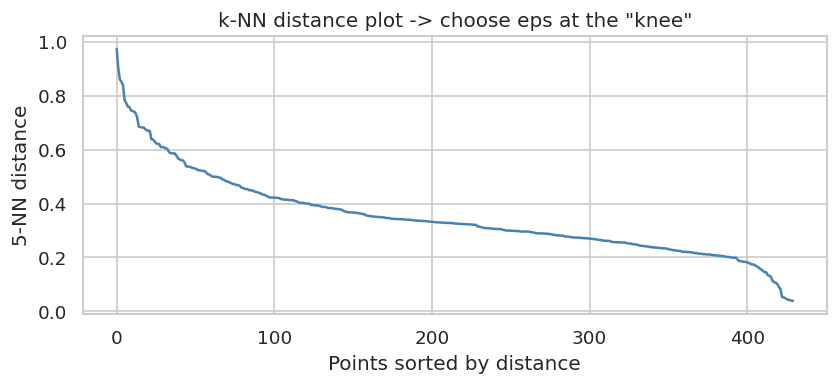

   eps  n_clusters   noise_pct   silhouette
---------------------------------------------
  0.20           1       86.0%          ---
  0.22           1       77.9%          ---
  0.24           2       69.3%       0.2337
  0.26           2       61.6%       0.4794
  0.28           3       51.2%       0.3570
  0.30           3       41.2%       0.3075
  0.32           3       36.7%       0.2848
  0.34           4       29.1%       0.2498
  0.36           2       25.3%       0.4930
  0.38           2       21.4%       0.4751
  0.40           2       18.1%       0.4600
  0.42           1       14.0%          ---
  0.44           1       12.8%          ---
  0.46           1       10.2%          ---
  0.48           1        9.5%          ---
  0.50           1        7.7%          ---
  0.52           1        6.7%          ---
  0.54           1        5.6%          ---
  0.56           1        4.9%          ---
  0.58           1        4.2%          ---

Selected eps = 0.36  (silhoue

In [24]:

MIN_SAMPLES = 5
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES)
nn.fit(X)
distances, _ = nn.kneighbors(X)
k_dist = np.sort(distances[:, -1])[::-1]

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(k_dist, color='steelblue')
ax.set_xlabel('Points sorted by distance')
ax.set_ylabel(f'{MIN_SAMPLES}-NN distance')
ax.set_title('k-NN distance plot -> choose eps at the "knee"')
plt.show()

eps_candidates = np.arange(0.20, 0.60, 0.02)
best_sil_db, best_eps, best_labels_dbscan = -1, None, None

print(f"{'eps':>6}  {'n_clusters':>10}  {'noise_pct':>10}  {'silhouette':>11}")
print('-' * 45)
for eps_val in eps_candidates:
    db_model = DBSCAN(eps=eps_val, min_samples=MIN_SAMPLES)
    lbl = db_model.fit_predict(X)
    n_clusters = len(set(lbl)) - (1 if -1 in lbl else 0)
    n_noise = int((lbl == -1).sum())
    if n_clusters < 2:
        print(f'{eps_val:6.2f}  {n_clusters:>10}  {n_noise/len(lbl)*100:>9.1f}%  {"---":>11}')
        continue
    core_mask = lbl != -1
    if core_mask.sum() < 2 or len(set(lbl[core_mask])) < 2:
        continue
    sil = silhouette_score(X[core_mask], lbl[core_mask])
    print(f'{eps_val:6.2f}  {n_clusters:>10}  {n_noise/len(lbl)*100:>9.1f}%  {sil:>11.4f}')
    if sil > best_sil_db:
        best_sil_db, best_eps, best_labels_dbscan = sil, eps_val, lbl.copy()

print(f'\nSelected eps = {best_eps:.2f}  (silhouette = {best_sil_db:.4f})')
n_dbscan_clusters = len(set(best_labels_dbscan)) - (1 if -1 in best_labels_dbscan else 0)
n_noise_final = int((best_labels_dbscan == -1).sum())
print(f'DBSCAN found {n_dbscan_clusters} clusters, {n_noise_final} noise points ({n_noise_final/len(best_labels_dbscan)*100:.1f}%)')
df_cross['cluster_dbscan'] = best_labels_dbscan
print(df_cross['cluster_dbscan'].value_counts().sort_index())

In [25]:
counts = df_cross['cluster_dbscan'].value_counts().sort_index()
print('DBSCAN cluster sizes:', dict(counts))

non_noise_counts = counts.drop(-1, errors='ignore')
small_id = non_noise_counts.idxmin()
print(f'\nSmall cluster (id={small_id}) members:')
print(df_cross.loc[df_cross['cluster_dbscan'] == small_id, ['kabkota', 'provinsi', 'is_kota']])


DBSCAN cluster sizes: {-1: np.int64(109), 0: np.int64(316), 1: np.int64(5)}

Small cluster (id=1) members:
                       kabkota        provinsi  is_kota
11     Kota Adm. Jakarta Barat     DKI Jakarta        1
13   Kota Adm. Jakarta Selatan     DKI Jakarta        1
14     Kota Adm. Jakarta Timur     DKI Jakarta        1
242                 Kota Medan  Sumatera Utara        1
396             Kab. Tangerang          Banten        1


### 6.5 PCA scatter — K-Means vs DBSCAN

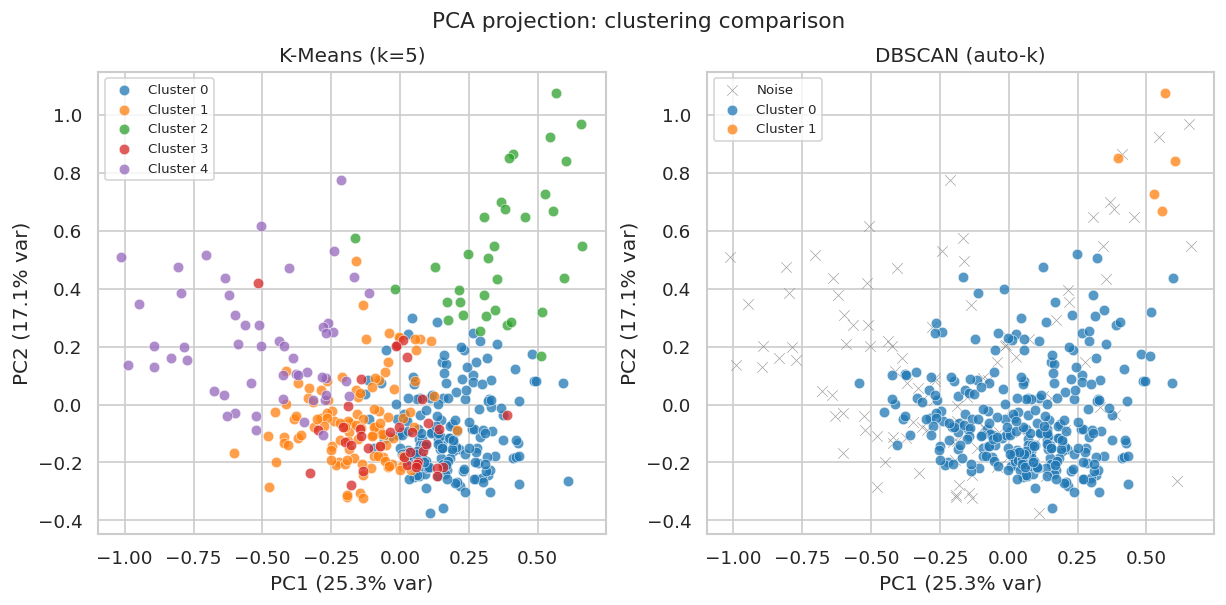

In [26]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

cluster_cols = ['cluster_kmeans', 'cluster_dbscan']
cluster_titles = ['K-Means (k=5)', 'DBSCAN (auto-k)']

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, col, title in zip(axes, cluster_cols, cluster_titles):
    unique_labels = sorted(df_cross[col].unique())
    palette_ext = sns.color_palette('tab10', len([l for l in unique_labels if l != -1]))
    color_idx = 0
    for k in unique_labels:
        mask = df_cross[col].values == k
        label = 'Noise' if k == -1 else f'Cluster {k}'
        color = 'gray'  if k == -1 else palette_ext[color_idx]
        marker = 'x'     if k == -1 else 'o'
        if k != -1: color_idx += 1
        ax.scatter(X_pca[mask, 0], X_pca[mask, 1], c=[color], label=label, s=40, alpha=0.75, marker=marker, edgecolors='white', linewidths=0.4)
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} var)')
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} var)')
    ax.set_title(title)
    ax.legend(fontsize=8)

plt.suptitle('PCA projection: clustering comparison', fontsize=13)
plt.show()

### 6.6 Cluster profiles (radar chart)

Cluster profiles:


,Food waste,Wood/twigs,Paper/cardboard,Plastic,Metal,Textile,Rubber/leather,Glass,Other,Daily generation,Population,Density (per km2),GRDP per capita
cluster_kmeans,,,,,,,,,,,,,
0,50.41,9.40,10.07,16.65,2.12,1.96,1.58,1.77,6.89,201.43,438857.51,1895.27,5.621185e+07
1,29.12,20.32,12.10,20.26,3.93,2.63,2.29,2.14,7.74,200.31,433836.46,1847.24,4.818915e+07
2,49.88,7.89,10.08,17.09,1.46,3.66,1.60,1.79,7.79,1212.53,2009711.61,3292.89,8.158152e+07
3,39.82,10.61,10.88,18.88,2.95,2.48,1.99,2.54,9.79,135.44,268408.11,6995.43,1.866442e+08
4,26.01,11.97,12.55,20.84,5.90,5.50,4.63,5.24,7.77,185.68,412446.21,2320.96,5.784075e+07


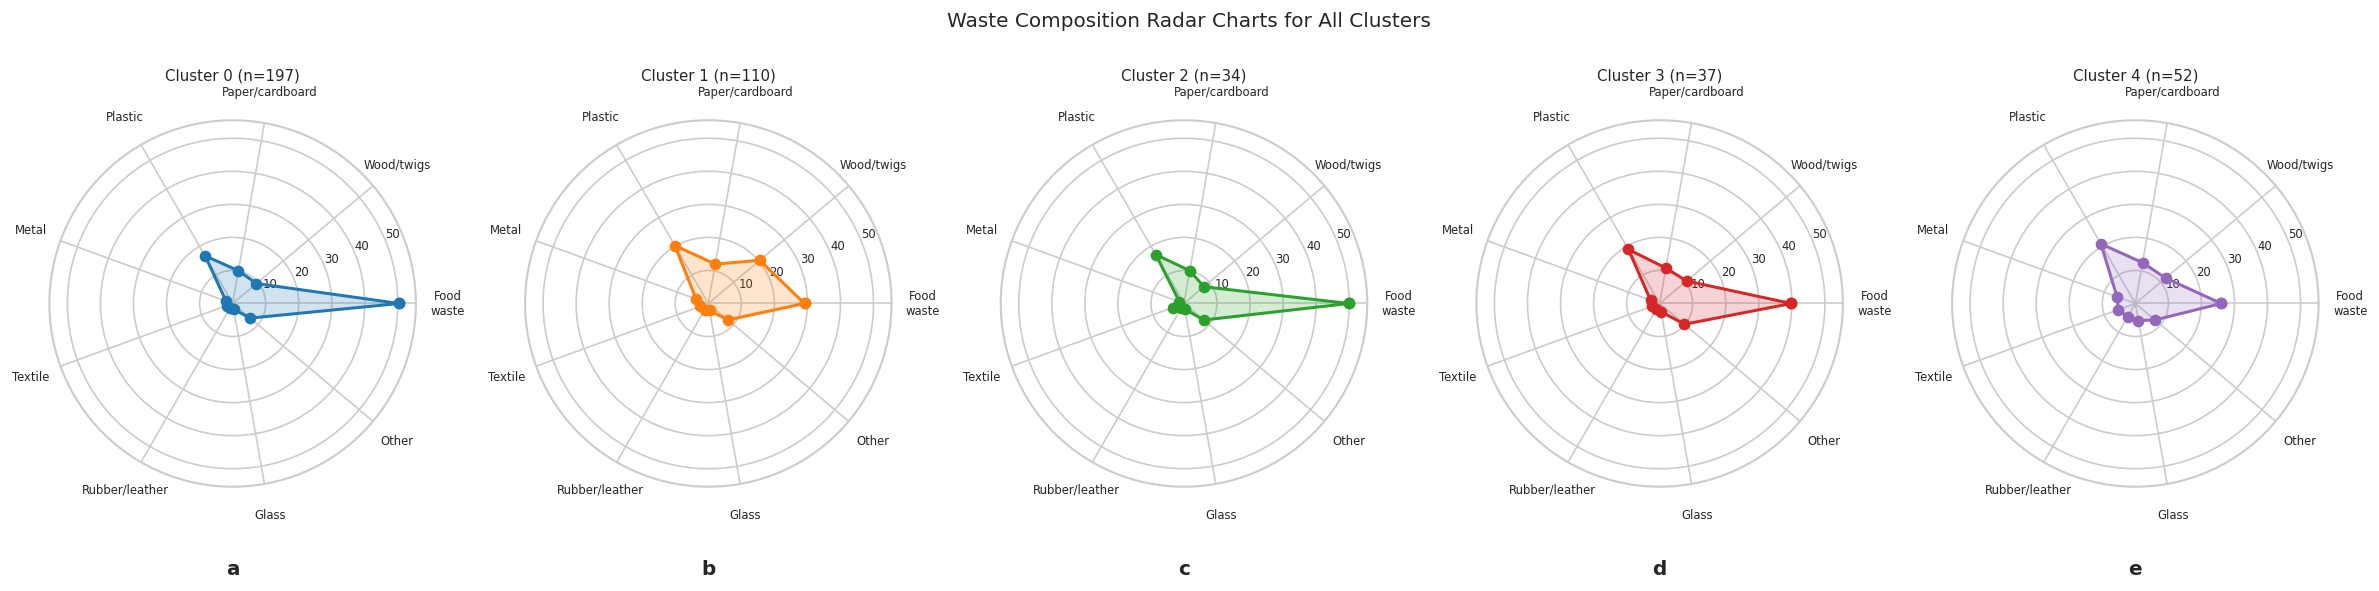

In [46]:
cluster_profiles = (
    df_cross.groupby('cluster_kmeans')[FEATURE_COLS]
    .mean().round(2)
)
print('Cluster profiles:')
display(cluster_profiles.rename(columns=DISPLAY_LABELS))

cats = WASTE_COLS
N = len(cats)
angles = np.linspace(0, 2*np.pi, N, endpoint=False).tolist() + [0]

palette = sns.color_palette('tab10', BEST_K)

fig, axes = plt.subplots(1, BEST_K, figsize=(BEST_K * 4, 4.6), subplot_kw=dict(polar=True))

alphabets = ['a', 'b', 'c', 'd', 'e']

for k in range(BEST_K):
    ax = axes[k] if BEST_K > 1 else axes

    vals = cluster_profiles.loc[k, cats].tolist() + [cluster_profiles.loc[k, cats[0]]]
    ax.plot(angles, vals, 'o-', lw=1.8, color=palette[k])
    ax.fill(angles, vals, alpha=0.2, color=palette[k])
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels([DISPLAY_LABELS.get(c, c).replace(' ','\n') for c in cats], size=7)
    ax.tick_params(axis='x', pad=6)
    ax.tick_params(axis='y', labelsize=7)
    n = df_cross[df_cross.cluster_kmeans==k].shape[0]
    ax.set_title(f'Cluster {k} (n={n})', size=9, pad=24)
    ax.set_ylim(0, cluster_profiles[cats].values.max() * 1.1)

    ax.text(0.5, -0.2, alphabets[k],
            transform=ax.transAxes,
            ha='center', va='top', fontsize=12, weight='bold')

fig.suptitle('Waste Composition Radar Charts for All Clusters', fontsize=12, y=1.02)
fig.tight_layout()
plt.show()

### 6.7 Validation metrics —> K-Means vs DBSCAN

In [52]:
print(f"{'Method':<20} {'Silhouette':>12} {'Davies-Bouldin':>16} {'Calinski-H':>13}")
print('-' * 65)
for name, labels, core_only in [
    ('K-Means', df_cross.cluster_kmeans.values, False),
    ('DBSCAN',  df_cross.cluster_dbscan.values, True),
]:
    mask = labels != -1 if core_only else np.ones(len(labels), dtype=bool)
    X_m, y_m = X[mask], labels[mask]
    if len(set(y_m)) < 2:
        continue
    sil = silhouette_score(X_m, y_m)
    db = davies_bouldin_score(X_m, y_m)
    ch = calinski_harabasz_score(X_m, y_m)
    print(f'{name:<20} {sil:>12.4f} {db:>16.4f} {ch:>13.2f}')

# C0: sisa_makanan=50%, plastik=17%, PDRB=56M, density=1895  → high-organic, low-income
# C1: sisa_makanan=32%, kayu_ranting=20.32% (HIGHEST), plastik=19%, PDRB=48M → wood/yard-dominant, likely forested/agricultural
# C2: sisa_makanan=50%, plastik=17%, PDRB=81M, density=3293, timbulan=1213 t/day → dense urban (Jakarta-class)
# C3: sisa_makanan=40%, plastik=19%, PDRB=187M, density=6995  → high-PDRB resource cities (e.g. Balikpapan)
# C4: sisa_makanan=26% (LOWEST), plastik=20.84% (HIGHEST), logam=5.90% (HIGHEST), kain=5.5% (HIGHEST) → industrial/commercial profile
CLUSTER_LABELS = {
    0: 'High organic / low income',
    1: 'Wood-dominant / rural-agricultural',
    2: 'Dense urban / high volume',
    3: 'High GRDP / resource-rich cities',
    4: 'Industrial / high non-organic / Commercial',
}
df_cross['cluster_label'] = df_cross['cluster_kmeans'].map(CLUSTER_LABELS)

df = df.drop(columns=[c for c in df.columns if c.startswith(('cluster_kmeans', 'cluster_label'))])
df = df.merge(df_cross[['kabkota_key','cluster_kmeans','cluster_label']], on='kabkota_key', how='left')


print('\nRegion per cluster:')
for k in range(BEST_K):
    names = df_cross[df_cross.cluster_kmeans==k]['kabkota'].values[0:]
    print(f'  Cluster {k}: {CLUSTER_LABELS[k]}: {", ".join(names)}')

Method                 Silhouette   Davies-Bouldin    Calinski-H
-----------------------------------------------------------------
K-Means                    0.1690           1.7714         64.36
DBSCAN                     0.4930           0.5747         31.51

Region per cluster:
  Cluster 0: High organic / low income: Kab. Aceh Barat, Kab. Aceh Jaya, Kab. Aceh Tamiang, Kab. Agam, Kab. Asahan, Kab. Balangan, Kab. Bangka Barat, Kab. Bangka Tengah, Kab. Bangkalan, Kota Banjarbaru, Kab. Bantul, Kab. Banyuasin, Kab. Barito Kuala, Kab. Barito Selatan, Kab. Barru, Kota Batu, Kab. Belitung Timur, Kab. Bengkayang, Kota Bengkulu, Kab. Bengkulu Tengah, Kab. Bireuen, Kota Bitung, Kab. Blitar, Kab. Bojonegoro, Kab. Bolaang Mongondow, Kab. Bondowoso, Kab. Bone, Kota Bontang, Kota Bukittinggi, Kab. Bungo, Kab. Buol, Kab. Buton Selatan, Kab. Buton Tengah, Kota Cilegon, Kota Cimahi, Kab. Dairi, Kab. Demak, Kab. Dharmasraya, Kota Dumai, Kab. Empat Lawang, Kab. Fak Fak, Kab. Gowa, Kab. Gresik, Kab. Gun

### 6.8 Full comparison — K-Means vs DBSCAN
We compare both approaches using three standard internal validation indices:
| Metric | Direction | What it measures |
|--------|-----------|------------------|
| **Silhouette** | ↑ higher | Cohesion vs separation (−1 to +1) |
| **Davies-Bouldin** | ↓ lower | Intra-cluster scatter vs inter-cluster separation |
| **Calinski-Harabasz** | ↑ higher | Between-cluster / within-cluster dispersion ratio |

In [38]:
if 'cluster_dbscan' not in df_cross.columns:
    raise RuntimeError('Run DBSCAN cell first (section 6.4)')

results_cmp = []
for method_name, labels in [
    ('K-Means (k=5)', df_cross['cluster_kmeans'].values),
    ('DBSCAN',          df_cross['cluster_dbscan'].values),
]:
    core_mask = labels != -1
    X_eval, y_eval = X[core_mask], labels[core_mask]
    n_clusters = len(set(y_eval))
    n_noise = int((labels == -1).sum())
    if n_clusters < 2:
        results_cmp.append({'Method': method_name, 'k_found': n_clusters,
                             'Noise points': n_noise, 'Silhouette': np.nan,
                             'Davies-Bouldin': np.nan, 'Calinski-Harabasz': np.nan})
        continue
    sil = silhouette_score(X_eval, y_eval)
    db = davies_bouldin_score(X_eval, y_eval)
    ch = calinski_harabasz_score(X_eval, y_eval)
    results_cmp.append({'Method': method_name, 'k_found': n_clusters,
                         'Noise points': n_noise,
                         'Silhouette': round(sil, 4),
                         'Davies-Bouldin': round(db, 4),
                         'Calinski-Harabasz': round(ch, 2)})

df_metrics_cmp = pd.DataFrame(results_cmp).set_index('Method')
print('=== Internal Validation Metrics (K-Means vs DBSCAN) ===')
display(df_metrics_cmp)

=== Internal Validation Metrics (K-Means vs DBSCAN) ===


,k_found,Noise points,Silhouette,Davies-Bouldin,Calinski-Harabasz
Method,,,,,
K-Means (k=5),5,0,0.169,1.7714,64.36
DBSCAN,2,109,0.493,0.5747,31.51


### 6.9 Bar chart comparison

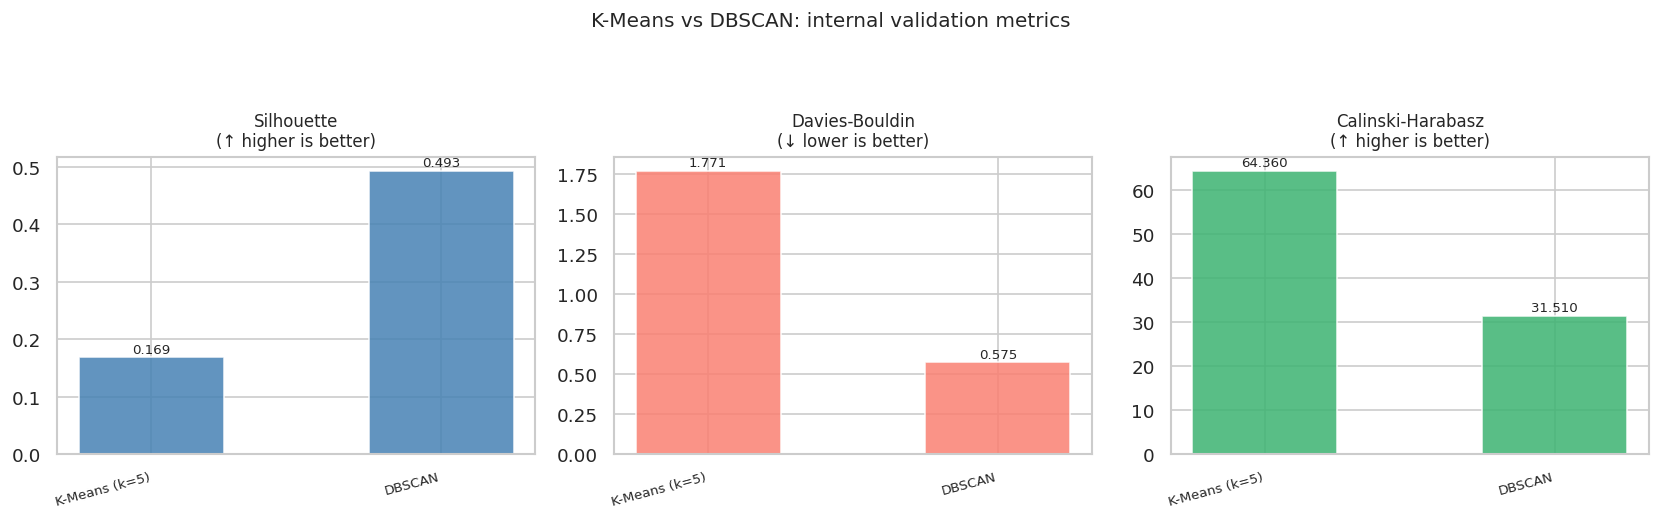

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
metric_info = [
    ('Silhouette', '↑ higher is better', 'steelblue'),
    ('Davies-Bouldin', '↓ lower is better',  'salmon'),
    ('Calinski-Harabasz', '↑ higher is better', 'mediumseagreen'),
]

methods_plot = df_metrics_cmp.index.tolist()
x = np.arange(len(methods_plot))

for ax, (metric, note, color) in zip(axes, metric_info):
    vals = df_metrics_cmp[metric].values.astype(float)
    bars = ax.bar(x, vals, color=color, edgecolor='white', alpha=0.85, width=0.5)
    ax.set_xticks(x)
    ax.set_xticklabels(methods_plot, rotation=15, ha='right', fontsize=8)
    ax.set_title(f'{metric}\n({note})', fontsize=10)
    for bar, v in zip(bars, vals):
        if not np.isnan(v):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005 * np.nanmax(vals), f'{v:.3f}', ha='center', va='bottom', fontsize=8)

plt.suptitle('K-Means vs DBSCAN: internal validation metrics', fontsize=12, y=1.08)
plt.tight_layout()
plt.show()

## 8. Feature importance

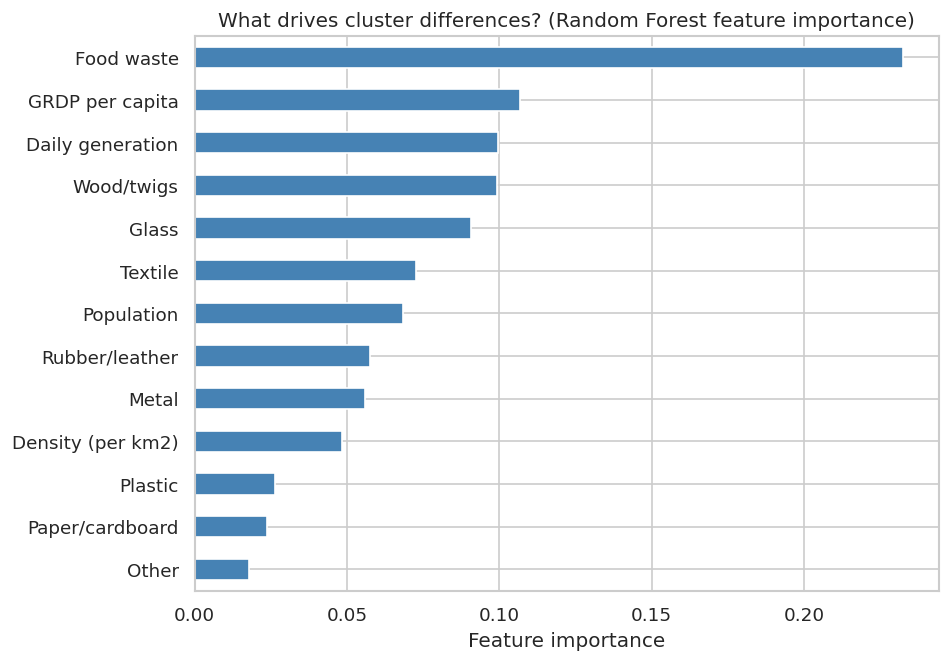

Top 5 drivers:
Food waste          0.232462
GRDP per capita     0.106819
Daily generation    0.099587
Wood/twigs          0.099175
Glass               0.090821
dtype: float64


In [31]:
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X, df_cross['cluster_kmeans'].values)

importances = pd.Series(rf.feature_importances_, index=FEATURE_COLS).rename(index=DISPLAY_LABELS).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 6))
importances.plot.barh(ax=ax, color='steelblue', edgecolor='white')
ax.set_xlabel('Feature importance')
ax.set_title('What drives cluster differences? (Random Forest feature importance)')
plt.show()

print('Top 5 drivers:')
print(importances.sort_values(ascending=False).head())

## 9. Regional profile summary table

In [37]:
table1 = (
    df_cross.groupby('cluster_kmeans')
    .agg(
        n_regions = ('kabkota_key', 'count'),
        n_cities = ('is_kota', 'sum'),
        food_waste = ('sisa_makanan', 'mean'),
        plastic = ('plastik', 'mean'),
        paper_cardboard = ('kertas_karton', 'mean'),
        grdp_per_capita = ('pdrb_per_kapita', 'mean'),
        density = ('kepadatan_km2', 'mean'),
        generation = ('timbulan_harian', 'mean'),
    ).round(2)
)
table1['cluster_label'] = table1.index.map(CLUSTER_LABELS)
table1['pct_city'] = (table1['n_cities'] / table1['n_regions'] * 100).round(0).astype(int)
print('TABLE I: Regional cluster characteristics:')
display(table1)

TABLE I: Regional cluster characteristics:


,n_regions,n_cities,food_waste,plastic,paper_cardboard,grdp_per_capita,density,generation,cluster_label,pct_city
cluster_kmeans,,,,,,,,,,
0,197,45,50.41,16.65,10.07,5.621185e+07,1895.27,201.43,High organic / low income,23
1,110,13,29.12,20.26,12.10,4.818915e+07,1847.24,200.31,Wood-dominant / rural-agricultural,12
2,34,16,49.88,17.09,10.08,8.158152e+07,3292.89,1212.53,Dense urban / high volume,47
3,37,4,39.82,18.88,10.88,1.866442e+08,6995.43,135.44,High GRDP / resource-rich cities,11
4,52,6,26.01,20.84,12.55,5.784075e+07,2320.96,185.68,Industrial / high non-organic / Commercial,12
